# Explainability

SHAP, LIME and a logistic-regression surrogate for a random forest on the 9-bus system. All methods are seeded and explain the model in the original feature units.

In [1]:
import numpy as np
import tranpy
from tranpy_core import make_pipeline, train_test_split
from tranpy_core.explain import explain_lime, explain_shap, fit_surrogate
from tranpy_core.plotting import plot_importance
from pathlib import Path
import matplotlib.pyplot as plt
from tranpy_core.plotting import publication_style, save_figure

FIGURES = Path("outputs")
plt.rcParams["figure.dpi"] = 150

In [2]:
data = tranpy.load_ieee_9bus()
split = train_test_split(data.labels, test_size=0.2, seed=42)
X_train, X_test = data.features[split.train], data.features[split.test]
model = make_pipeline("random_forest", seed=0).fit(X_train, data.labels[split.train])

## SHAP

In [3]:
shap_exp = explain_shap(model, X_test[:100], background=X_train, feature_names=data.feature_names, seed=0)
residual = shap_exp.base_values + shap_exp.attributions.sum(axis=1) - model.predict_proba(X_test[:100])[:, 1]
print("local accuracy, max |residual|:", np.abs(residual).max())
shap_exp.top_features(5)

local accuracy, max |residual|: 2.220446049250313e-15


,feature,importance
0,F_13,0.094461
1,F_5,0.050082
2,F_11,0.049690
3,F_6,0.038366
4,F_1,0.035475


## LIME

In [4]:
lime_exp = explain_lime(model, X_test[:20], background=X_train, num_samples=2000,
                        feature_names=data.feature_names, class_names=tranpy.LABEL_NAMES, seed=0)
lime_exp.top_features(5)

,feature,importance
0,F_13,0.111441
1,F_11,0.053634
2,F_14,0.041838
3,F_5,0.034364
4,F_3,0.032809


## Global surrogate

In [5]:
surrogate = fit_surrogate(model, X_train, X_test, y_eval=data.labels[split.test], feature_names=data.feature_names)
print(f"fidelity {surrogate.fidelity:.3f}, accuracy {surrogate.accuracy:.3f}")
surrogate.top_features(5)

fidelity 0.966, accuracy 0.970


,feature,importance,coefficient
0,F_14,4.985290,-4.985290
1,F_13,3.720836,-3.720836
2,F_1,3.328787,-3.328787
3,F_10,2.623500,-2.623500
4,F_5,2.405284,-2.405284


## Do the methods agree?

In [6]:
import pandas as pd

pd.DataFrame({"shap": shap_exp.ranking()[:8], "lime": lime_exp.ranking()[:8], "surrogate": surrogate.ranking()[:8]})

,shap,lime,surrogate
0,F_13,F_13,F_14
1,F_5,F_11,F_13
2,F_11,F_14,F_1
3,F_6,F_5,F_10
4,F_1,F_3,F_5
5,F_0,F_0,F_7
6,F_14,F_6,F_8
7,F_4,F_4,F_0


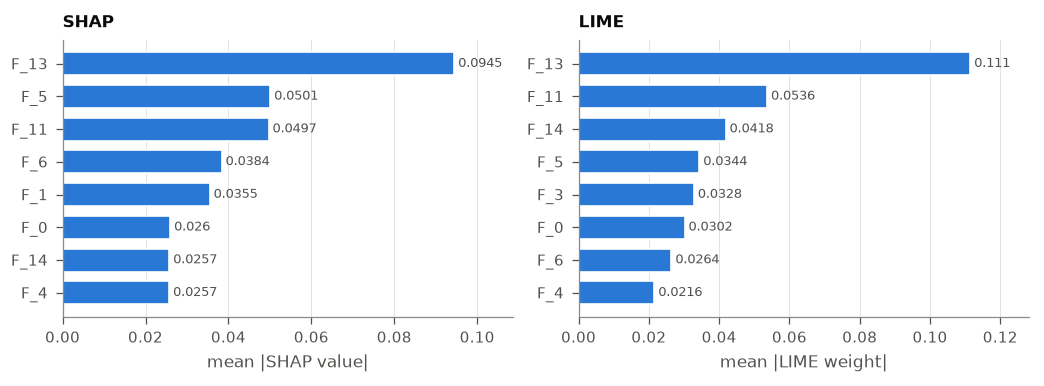

In [7]:
with publication_style():
    fig, axes = plt.subplots(1, 2, figsize=(7.0, 2.6))
    plot_importance(shap_exp.feature_names, shap_exp.importance(), top=8, ax=axes[0], title="SHAP", xlabel="mean |SHAP value|")
    plot_importance(lime_exp.feature_names, lime_exp.importance(), top=8, ax=axes[1], title="LIME", xlabel="mean |LIME weight|")
    fig.tight_layout()
    save_figure(fig, FIGURES / "04_importance.pdf")
plt.show()